In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import fixed_quad
from scipy.optimize import brentq
from sklearn.metrics import mean_squared_error
from merton.extensions.creditgrades import creditgrades_survival

In [2]:
df = pd.read_csv("../Data/aggregation/BA_for_CG.csv", parse_dates=["Date"])
df = df[df.Date.between("2018-01-01", "2025-01-01", inclusive="neither")]
df = df.dropna(subset=["Close", "IV", "Z", "rf", "STD", "LTD", "Shares"])
df["T"] = (pd.Timestamp("2038-02-15") - df.Date).dt.days / 365.25
df["D"] = (df.STD + df.LTD) / df.Shares
df["r"] = df.rf / 100

In [3]:
def cg_spread(S, vol, D, T, r):
    def discounted_survival(u):
        return np.exp(-r * u) * creditgrades_survival(S, vol, D, u)

    annuity = fixed_quad(discounted_survival, 0, T, n=64)[0]
    return 0.6 * ((1 - discounted_survival(T)) / annuity - r) * 10000 * 360 / 365.25

def calibrate_z(S, Z, D, T, r):
    return brentq(lambda vol: cg_spread(S, vol, D, T, r) - Z, 1e-6, 5)

In [4]:
result = df[["Date", "Z", "IV"]].rename(columns={"Z": "Z_spread"})
result[["CDS_from_IV", "IV_from_Z"]] = [
    (cg_spread(S, IV, D, T, r), calibrate_z(S, Z, D, T, r))
    for S, IV, Z, D, T, r in df[["Close", "IV", "Z", "D", "T", "r"]].itertuples(index=False, name=None)
]
result

,Date,Z_spread,IV,CDS_from_IV,IV_from_Z
503,2018-01-02,109.249072,0.23815,1.050279,0.482977
504,2018-01-03,107.415780,0.23405,0.858552,0.480873
505,2018-01-04,109.310532,0.23390,0.859998,0.482922
506,2018-01-05,99.885654,0.23575,0.846909,0.474409
507,2018-01-08,106.192629,0.23915,0.982823,0.482665
...,...,...,...,...,...
2259,2024-12-24,153.571425,0.37495,129.261760,0.397360
2260,2024-12-26,154.236880,0.37085,124.508866,0.398408
2261,2024-12-27,155.135377,0.36860,121.873558,0.399518
2262,2024-12-30,146.711071,0.36270,117.801884,0.389973


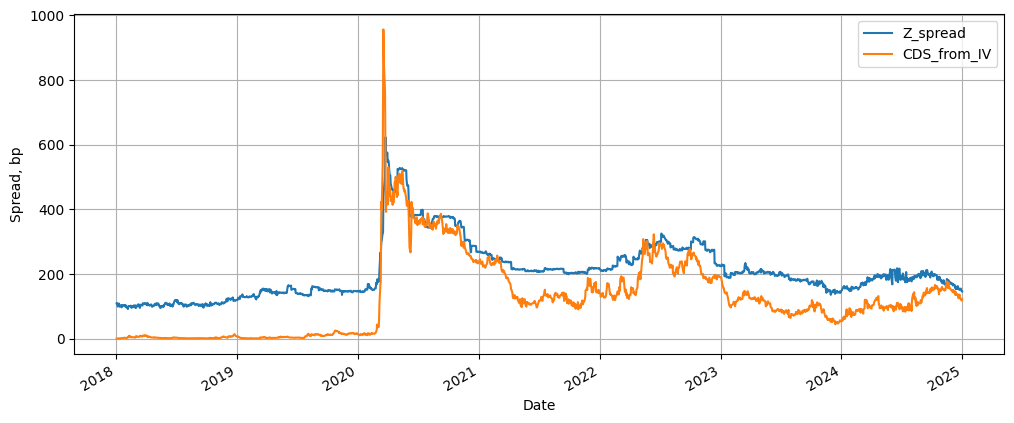

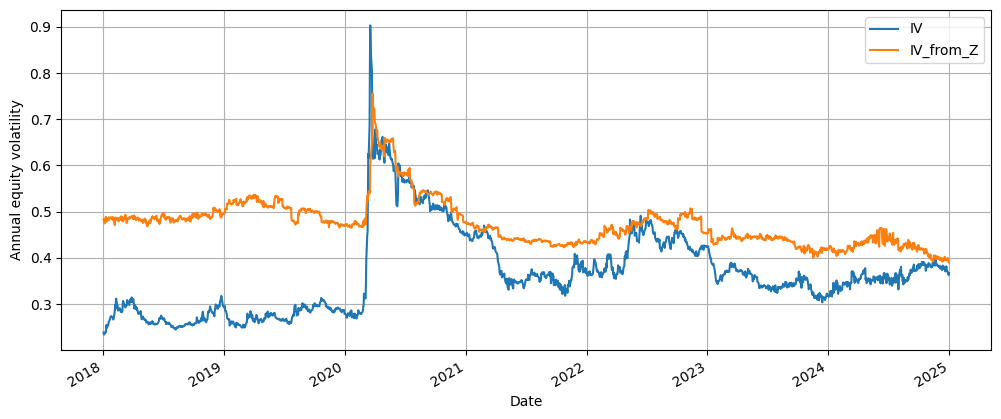

In [5]:
ax = result.plot(x="Date", y=["Z_spread", "CDS_from_IV"], figsize=(12, 5), grid=True)
ax.set_ylabel("Spread, bp")
plt.show()

ax = result.plot(x="Date", y=["IV", "IV_from_Z"], figsize=(12, 5), grid=True)
ax.set_ylabel("Annual equity volatility")
plt.show()

In [9]:
mse = mean_squared_error(result['IV'], result["IV_from_Z"])
ll = -len(result) / 2 * (np.log(2 * np.pi * mse) + 1)
print(mse)
print(ll)

0.01840343985313188
1019.0384131723285
